# Exploratory Analysis of Quantum Dot Blinking

## Dataset
qdb_20260824_102327.raw

## Aim
Explore the spatial and temporal fluorescence characteristics
of detected quantum dot candidates.

Initially, compare differences in brightness, fitted width,
and fluorescence variability.

## Research context
This analysis builds on the methods in
*A practical guide for wide-field imaging of quantum dot blinking*.

The aim is to investigate which measurements might eventually
help distinguish isolated emitters from unresolved clusters.

Candidate detection does not establish the number of quantum dots.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find results from the selected experimental recording
results_root = Path("qd_blinking_results")

folders = sorted(
    results_root.glob("qdb_20260824_102327_raw_*"),
    key=lambda p: p.stat().st_mtime
)

if not folders:
    raise FileNotFoundError("No experimental analysis results found.")

folder = folders[-1]

# Load previously exported results
candidates = pd.read_csv(folder / "retained_candidates.csv")
statistics = pd.read_csv(folder / "trace_statistics.csv")
traces = pd.read_csv(folder / "extracted_traces.csv")

print("Dataset:", folder.name)
print("Retained candidates:", len(candidates))
print("Extracted traces:", traces["candidate_id"].nunique())
print("Total measurements:", len(traces))

Dataset: qdb_20260824_102327_raw_20261020T145929_676324Z
Retained candidates: 168
Extracted traces: 168
Total measurements: 168000


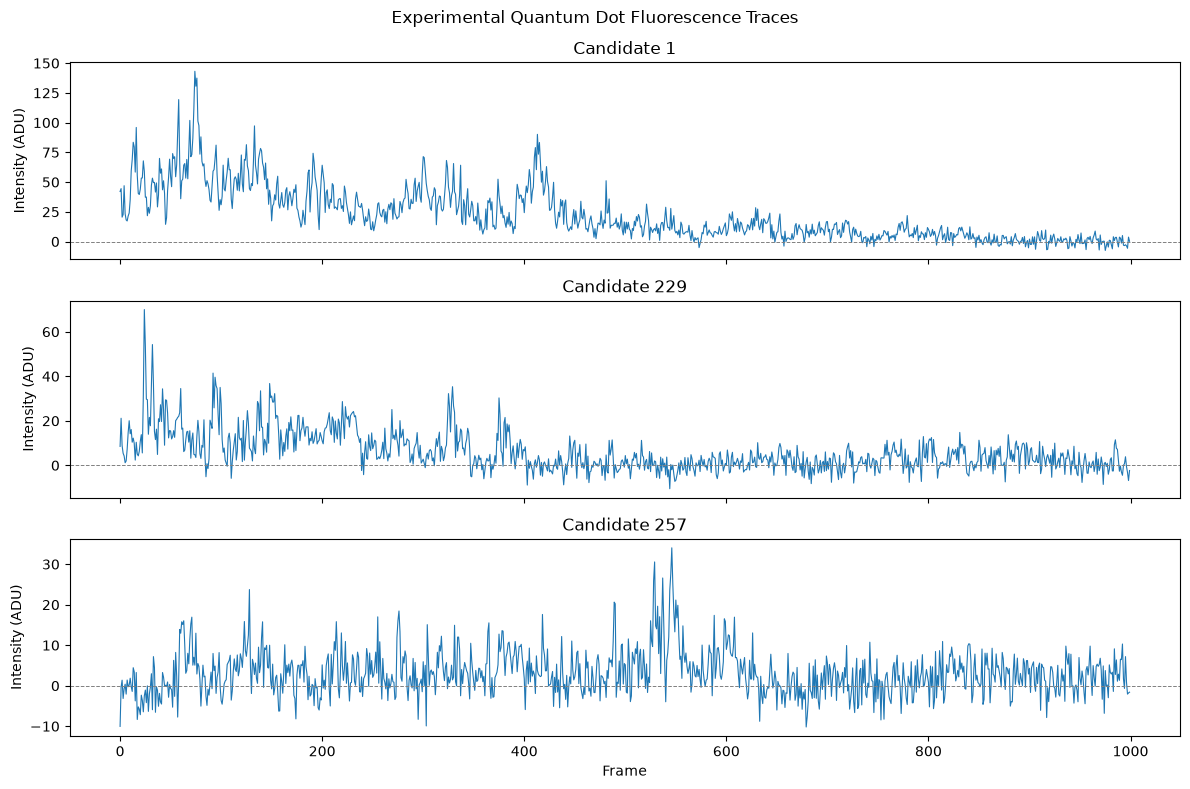

In [2]:
candidate_ids = [1, 229, 257]

fig, axes = plt.subplots(
    len(candidate_ids), 1,
    figsize=(12, 8),
    sharex=True
)

for ax, cid in zip(axes, candidate_ids):
    trace = traces[traces["candidate_id"] == cid]

    if trace["time_s"].notna().all():
        x = trace["time_s"]
        xlabel = "Time (s)"
    else:
        x = trace["frame"]
        xlabel = "Frame"

    ax.plot(
        x,
        trace["corrected_mean_counts"],
        linewidth=0.8
    )

    ax.axhline(0, linestyle="--", color="gray", linewidth=0.7)
    ax.set_ylabel("Intensity (ADU)")
    ax.set_title(f"Candidate {cid}")

axes[-1].set_xlabel(xlabel)

fig.suptitle("Experimental Quantum Dot Fluorescence Traces")
plt.tight_layout()
plt.show()

## Temporal changes in fluorescence intensity

The experimental traces exhibit substantial changes in
fluorescence intensity over time.

To investigate these changes, the mean corrected intensity
during the first and last 200 frames is compared.

This provides a descriptive measurement of temporal
brightness changes but does not independently establish
photobleaching or any particular blinking mechanism.

In [3]:
# Compare the beginning and end of each fluorescence trace

results = []

for cid, group in traces.groupby("candidate_id"):

    group = group.sort_values("frame")
    intensity = group["corrected_mean_counts"].to_numpy()

    early_mean = intensity[:200].mean()
    late_mean = intensity[-200:].mean()

    results.append({
        "candidate_id": cid,
        "early_mean": early_mean,
        "late_mean": late_mean,
        "intensity_change": late_mean - early_mean
    })

temporal_summary = pd.DataFrame(results)

display(
    temporal_summary[
        temporal_summary["candidate_id"].isin([1, 229, 257])
    ].round(2)
)

,candidate_id,early_mean,late_mean,intensity_change
0,1,51.24,1.80,-49.44
147,229,15.34,2.57,-12.78
163,257,2.32,2.51,0.18


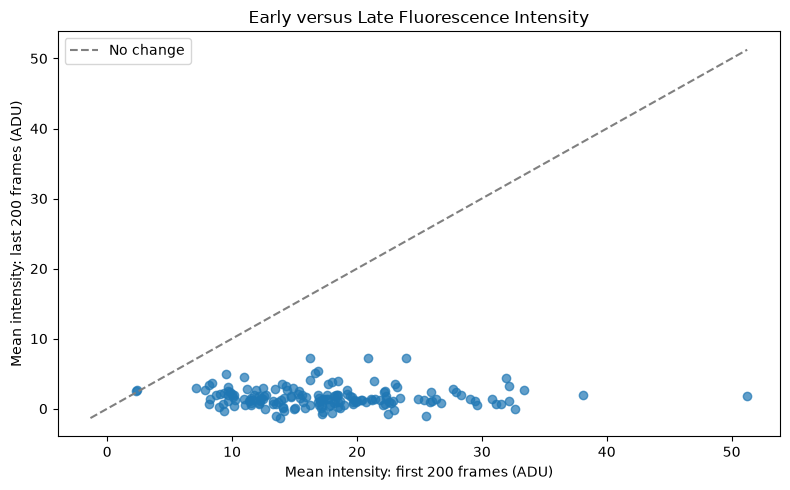

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    temporal_summary["early_mean"],
    temporal_summary["late_mean"],
    alpha=0.7
)

low = min(
    temporal_summary["early_mean"].min(),
    temporal_summary["late_mean"].min()
)

high = max(
    temporal_summary["early_mean"].max(),
    temporal_summary["late_mean"].max()
)

ax.plot([low, high], [low, high],
        linestyle="--", color="gray",
        label="No change")

ax.set_xlabel("Mean intensity: first 200 frames (ADU)")
ax.set_ylabel("Mean intensity: last 200 frames (ADU)")
ax.set_title("Early versus Late Fluorescence Intensity")
ax.legend()

plt.tight_layout()
plt.show()

## Population-wide fluorescence evolution

The early-versus-late comparison suggests that many detected
fluorescent features become dimmer during the recording.

To investigate whether this behaviour is shared across the
candidate population, the mean and median background-corrected
intensity are calculated for every frame.

These statistics describe the detected candidate population.
They do not establish the physical cause of fluorescence loss.

Potential explanations include photobleaching, photodarkening,
long-lived dark states and changes in experimental conditions.

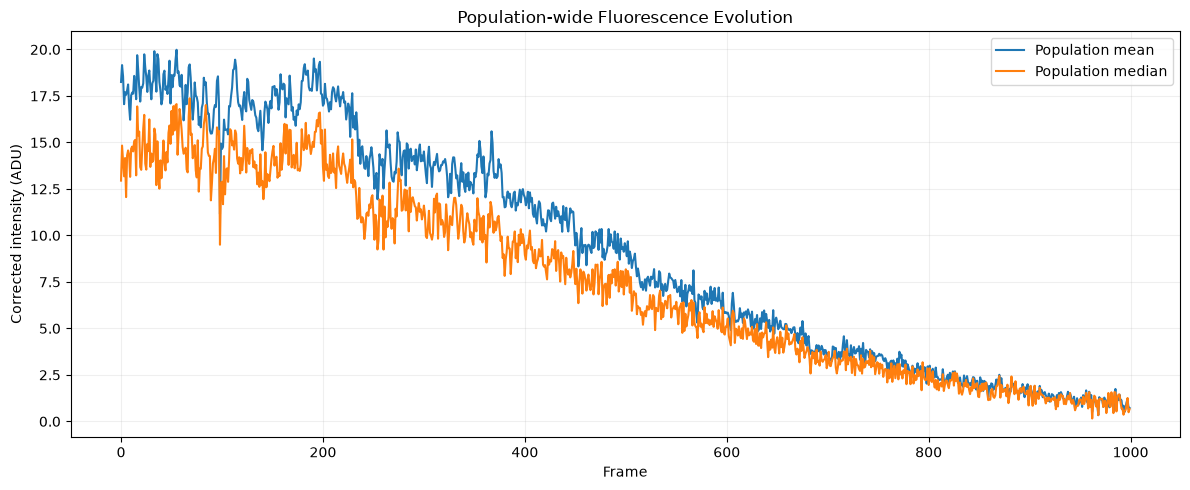

In [5]:
# Calculate population-wide fluorescence statistics

population = (
    traces.groupby("frame")["corrected_mean_counts"]
    .agg(["mean", "median", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    population["frame"],
    population["mean"],
    label="Population mean",
    linewidth=1.5
)

ax.plot(
    population["frame"],
    population["median"],
    label="Population median",
    linewidth=1.5
)

ax.set_xlabel("Frame")
ax.set_ylabel("Corrected intensity (ADU)")
ax.set_title("Population-wide Fluorescence Evolution")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Population-Wide Fluorescence Evolution

The graph shows the mean and median background-corrected fluorescence intensity across all 168 retained candidates over the 1,000-frame recording.

Both the population mean (blue) and median (orange) show a substantial decrease in fluorescence intensity over time, falling from approximately 18 and 14 ADU respectively to around 1 ADU by the end of the recording. Although short-term fluctuations are present, the overall trend is a progressive reduction in fluorescence across the candidate population.

The mean remains consistently above the median, particularly during the early frames, suggesting that a subset of brighter candidates contributes disproportionately to the average intensity.

This behaviour could be consistent with **photobleaching or photodarkening**, where quantum dots lose fluorescence under sustained illumination. However, changes in experimental conditions, such as excitation intensity or focus drift, could also contribute. Further investigation would be required to determine the physical cause.

### Summary of Exploratory Analysis So Far

- Successfully reproduced the original analysis pipeline on the experimental recording `qdb_20260824_102327.raw`.
- Detected **264 fluorescent features**, of which **168 passed the Gaussian-fitting and quality-selection criteria**.
- Extracted 1,000-frame background-corrected intensity traces for all 168 retained candidates.
- Examined individual candidates, identifying considerable differences in brightness, intensity fluctuations and temporal behaviour.
- Compared the first and last 200 frames, finding that most candidates exhibited a substantial reduction in fluorescence intensity.
- Confirmed through population-wide analysis that fluorescence generally decreases throughout the recording.

### Initial Conclusions

The experimental traces exhibit considerably more complex behaviour than the synthetic demonstration data. In particular, the widespread decline in fluorescence suggests that time-dependent intensity changes may need to be accounted for when developing automated blinking analysis methods.

These observations provide an initial understanding of the dataset and highlight important considerations for future work, particularly the challenge of distinguishing individual quantum dots from unresolved clusters using their fluorescence behaviour.